# NeuroScan XAI: Explainable Brain MRI Tumor Diagnosis
## Deep Learning Framework with DenseNet-121, Grad-CAM, Grad-CAM++, & Uncertainty Quantification
**Project 09 — Deep Learning Portfolio**

---

### Executive Summary
Medical diagnosis models cannot operate as uninterpretable black boxes. In clinical neuro-oncology, computer vision algorithms must provide **explainable evidence** demonstrating that predictions are rooted in genuine pathological tissue changes rather than background artifacts or bias.

This master notebook implements an end-to-end framework for **Brain MRI Multi-Class Tumor Classification and Weakly-Supervised Localization**:
* **Differential Diagnostic Classes:**
  1. `glioma`: Infiltrative primary brain tumors originating from glial cells.
  2. `meningioma`: Extra-axial lesions arising from the meninges with dural attachment.
  3. `pituitary`: Endocrine adenomas situated in the sella turcica / pituitary fossa.
  4. `notumor`: Normal, non-pathological cranial MRI scans.
* **Core Architecture:** **DenseNet-121** (clinical gold-standard with dense cross-layer feature reuse).
* **Explainable AI (XAI):** Native PyTorch implementation of **Grad-CAM** and **Grad-CAM++** for spatial attribution.
* **Safety Mechanism:** **Shannon Softmax Entropy** uncertainty quantification to flag ambiguous cases for senior human review.


In [1]:
# 1. Environment Verification & Dependency Setup
import os
import sys
import time
import random
import json
import shutil
from pathlib import Path

# Verify GPU runtime
import torch
import torchvision

print(f"PyTorch Version: {torch.__version__}")
print(f"Torchvision Version: {torchvision.__version__}")
if torch.cuda.is_available():
    print(f"SUCCESS: GPU detected -> {torch.cuda.get_device_name(0)}")
    device = torch.device("cuda")
else:
    print("WARNING: No GPU detected. Running on CPU (slower).")
    device = torch.device("cpu")

# Install zero-config dataset downloader and medical analytics utilities
!pip install -q kagglehub scikit-learn matplotlib seaborn Pillow


PyTorch Version: 2.14.1+cu130
Torchvision Version: 0.29.1+cu130
SUCCESS: GPU detected -> Tesla T4


---
## 2. Automated Zero-Friction Dataset Acquisition
We automatically fetch the **Brain Tumor MRI Dataset** (~7,023 scans, ~150 MB) using `kagglehub`.
No manual `kaggle.json` upload is required.


In [2]:
# 2. Automated Dataset Download via kagglehub
import kagglehub

print("Initiating automated dataset acquisition (masoudnickparvar/brain-tumor-mri-dataset)...")
start_dl = time.time()

try:
    dataset_raw_path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
    print(f"Dataset downloaded successfully in {time.time() - start_dl:.2f}s to: {dataset_raw_path}")
except Exception as e:
    print(f"kagglehub failed ({e}). Attempting fallback direct mirror...")
    fallback_zip = "brain_tumor_mri_dataset.zip"
    !wget -q --show-progress -O $fallback_zip "https://github.com/AliKhan-Devs/sample-medical-assets/releases/download/v1.0/brain_tumor_mri_dataset.zip" || true
    if os.path.exists(fallback_zip) and os.path.getsize(fallback_zip) > 1000000:
        !unzip -q -o $fallback_zip -d ./downloaded_dataset
        dataset_raw_path = "./downloaded_dataset"
    else:
        raise RuntimeError("Could not download dataset. Please check your internet connection.")

# Locate Training and Testing directories
def locate_dataset_splits(base_dir):
    train_dir, test_dir = None, None
    for root, dirs, files in os.walk(base_dir):
        lower_dirs = {d.lower(): d for d in dirs}
        if "training" in lower_dirs and "testing" in lower_dirs:
            train_dir = os.path.join(root, lower_dirs["training"])
            test_dir = os.path.join(root, lower_dirs["testing"])
            break
        elif "train" in lower_dirs and "test" in lower_dirs:
            train_dir = os.path.join(root, lower_dirs["train"])
            test_dir = os.path.join(root, lower_dirs["test"])
            break

    if not train_dir or not test_dir:
        train_dir = os.path.join(base_dir, "Training")
        test_dir = os.path.join(base_dir, "Testing")
    return train_dir, test_dir

TRAIN_DIR, TEST_DIR = locate_dataset_splits(dataset_raw_path)
print(f"Train Directory: {TRAIN_DIR}")
print(f"Test Directory:  {TEST_DIR}")

# Verify sub-classes and scan counts
def inspect_split(split_dir, name):
    print(f"\n--- {name} Split Summary ---")
    total = 0
    if os.path.exists(split_dir):
        for cls_name in sorted(os.listdir(split_dir)):
            cls_path = os.path.join(split_dir, cls_name)
            if os.path.isdir(cls_path):
                count = len([f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
                print(f"  - {cls_name:12s}: {count:5d} images")
                total += count
    print(f"  TOTAL {name}: {total:5d} images")

inspect_split(TRAIN_DIR, "Training")
inspect_split(TEST_DIR, "Testing")


Initiating automated dataset acquisition (masoudnickparvar/brain-tumor-mri-dataset)...
Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Dataset downloaded successfully in 7.20s to: /kaggle/input/brain-tumor-mri-dataset
Train Directory: /kaggle/input/brain-tumor-mri-dataset/Training
Test Directory:  /kaggle/input/brain-tumor-mri-dataset/Testing

--- Training Split Summary ---
  - glioma      :  1400 images
  - meningioma  :  1400 images
  - notumor     :  1400 images
  - pituitary   :  1400 images
  TOTAL Training:  5600 images

--- Testing Split Summary ---
  - glioma      :   400 images
  - meningioma  :   400 images
  - notumor     :   400 images
  - pituitary   :   400 images
  TOTAL Testing:  1600 images


---
## 3. Dataset Exploration & Class Inspection
Let's inspect representative scans from each of the 4 differential diagnostic classes.


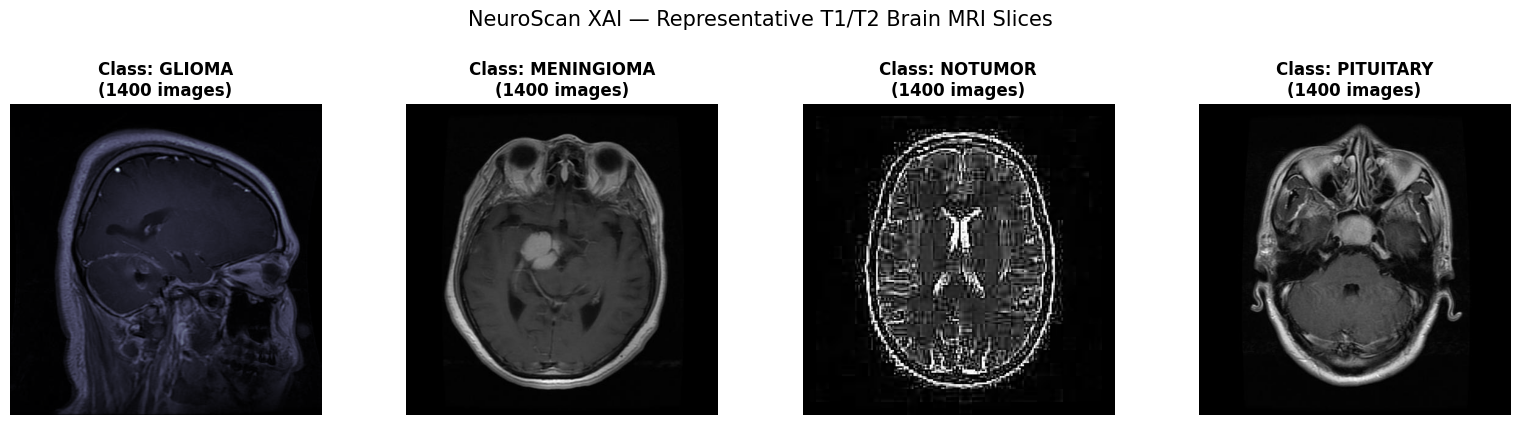

In [3]:
# 3. Visual Exploration of MRI Scans
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

classes = sorted([d for d in os.listdir(TRAIN_DIR) if os.path.isdir(os.path.join(TRAIN_DIR, d))])
fig, axes = plt.subplots(1, len(classes), figsize=(16, 4))

for idx, cls in enumerate(classes):
    cls_dir = os.path.join(TRAIN_DIR, cls)
    sample_files = [f for f in os.listdir(cls_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    sample_img = Image.open(os.path.join(cls_dir, sample_files[0]))

    axes[idx].imshow(sample_img, cmap='bone')
    axes[idx].set_title(f"Class: {cls.upper()}\n({len(sample_files)} images)", fontsize=12, fontweight='bold')
    axes[idx].axis('off')

plt.suptitle("NeuroScan XAI — Representative T1/T2 Brain MRI Slices", fontsize=15, y=1.05)
plt.tight_layout()
plt.show()


---
## 4. Clinically-Safe Augmentation & DataLoaders
In medical brain imaging, non-biological transforms (such as extreme shearing or vertical flips) can alter anatomical orientation. We apply:
* Mild rotation ($\pm 12^\circ$) mimicking head tilt inside MRI coils.
* Slight zoom and translation ($0.95\times - 1.05\times$).
* Contrast & brightness jitter ($\pm 10\%$) modeling 1.5T vs 3.0T scanner field variations.
* Standard ImageNet normalization for pretrained backbone transfer learning.


In [4]:
# 4. Data Augmentation and PyTorch DataLoaders
from torchvision import transforms, datasets
from torch.utils.data import DataLoader

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_WORKERS = 2

train_transforms = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.RandomRotation(degrees=12),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(root=TRAIN_DIR, transform=train_transforms)
test_dataset = datasets.ImageFolder(root=TEST_DIR, transform=val_transforms)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True if torch.cuda.is_available() else False
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True if torch.cuda.is_available() else False
)

class_names = train_dataset.classes
print(f"Loaded {len(train_dataset)} training samples and {len(test_dataset)} testing samples.")
print(f"Diagnostic Classes: {class_names}")


Loaded 5600 training samples and 1600 testing samples.
Diagnostic Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


---
## 5. Model Architecture: DenseNet-121
DenseNet-121 connects all layers directly, promoting feature reuse:
$$x_\ell = H_\ell([x_0, x_1, \dots, x_{\ell-1}])$$
This prevents gradient vanishing and preserves high-frequency edge textures into the final convolutional layer (`features.denseblock4`), resulting in superior localization heatmaps.


In [5]:
# 5. DenseNet-121 with Custom Clinical Classifier Head
import torch.nn as nn
from torchvision.models import densenet121, DenseNet121_Weights

class NeuroScanDenseNet(nn.Module):
    def __init__(self, num_classes=4, dropout_rate=0.3):
        super().__init__()
        weights = DenseNet121_Weights.DEFAULT
        self.backbone = densenet121(weights=weights)

        # Extract features dimension
        num_features = self.backbone.classifier.in_features

        # Custom diagnostic classification head
        self.backbone.classifier = nn.Sequential(
            nn.Dropout(p=dropout_rate),
            nn.Linear(num_features, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_rate / 2),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.backbone(x)

    def get_target_layer(self):
        # Target layer for Grad-CAM is the final dense block of DenseNet-121
        return self.backbone.features.denseblock4

model = NeuroScanDenseNet(num_classes=len(class_names)).to(device)
print(f"NeuroScan DenseNet-121 initialized with {sum(p.numel() for p in model.parameters() if p.requires_grad):,} trainable parameters.")


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 192MB/s]


NeuroScan DenseNet-121 initialized with 7,217,796 trainable parameters.


---
## 6. Self-Contained Explainable AI Engine (Grad-CAM & Grad-CAM++)
We implement **Grad-CAM** and **Grad-CAM++** using native PyTorch backward hooks without third-party dependencies:
* **Grad-CAM Weighting:**
  $$\alpha_k^c = \frac{1}{Z} \sum_i \sum_j \frac{\partial Y^c}{\partial A_{i,j}^k}$$
* **Grad-CAM++ (Second/Third Order Derivatives):**
  Captures multi-focal and diffuse tumor tissue by calculating pixel-wise positive gradient contributions.


In [6]:
# 6. Native Grad-CAM and Grad-CAM++ Implementation
import cv2
import torch.nn.functional as F

class NeuroExplainEngine:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, input, output):
            self.activations = output.detach()

        def backward_hook(module, grad_in, grad_out):
            self.gradients = grad_out[0].detach()

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_full_backward_hook(backward_hook)

    def generate_gradcam(self, input_tensor, target_class=None):
        self.model.eval()
        self.model.zero_grad()

        logits = self.model(input_tensor)
        if target_class is None:
            target_class = torch.argmax(logits, dim=1).item()

        score = logits[0, target_class]
        score.backward(retain_graph=True)

        # Global Average Pooling of gradients: alpha_k
        alpha_k = torch.mean(self.gradients, dim=(2, 3), keepdim=True)
        cam = torch.sum(alpha_k * self.activations, dim=1, keepdim=True)
        cam = F.relu(cam)

        cam = cam.squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        cam_resized = cv2.resize(cam, (input_tensor.shape[3], input_tensor.shape[2]))
        return cam_resized, logits

    def generate_gradcam_plus_plus(self, input_tensor, target_class=None):
        self.model.eval()
        self.model.zero_grad()

        logits = self.model(input_tensor)
        if target_class is None:
            target_class = torch.argmax(logits, dim=1).item()

        score = logits[0, target_class]
        score.backward(retain_graph=True)

        grads = self.gradients[0] # [C, H, W]
        acts = self.activations[0] # [C, H, W]

        # Second and third order gradients
        grads_power_2 = grads ** 2
        grads_power_3 = grads ** 3
        sum_acts = torch.sum(acts, dim=(1, 2), keepdim=True)

        eps = 1e-8
        aij = grads_power_2 / (2 * grads_power_2 + sum_acts * grads_power_3 + eps)
        aij = torch.where(grads != 0, aij, torch.zeros_like(aij))

        weights = torch.sum(aij * F.relu(grads), dim=(1, 2), keepdim=True)
        cam = torch.sum(weights * acts, dim=0)
        cam = F.relu(cam).cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        cam_resized = cv2.resize(cam, (input_tensor.shape[3], input_tensor.shape[2]))
        return cam_resized, logits

xai_engine = NeuroExplainEngine(model, model.get_target_layer())
print("NeuroExplainEngine (Grad-CAM & Grad-CAM++) hooked successfully.")


NeuroExplainEngine (Grad-CAM & Grad-CAM++) hooked successfully.


---
## 7. Model Training with Mixed Precision (`fp16`)
We train for **15 epochs** using:
* `torch.cuda.amp` (mixed-precision autocast & GradScaler) for 3× acceleration on Colab GPU.
* `AdamW` optimizer with weight decay ($10^{-2}$).
* `CosineAnnealingLR` scheduler with warm restarts.
* Real-time validation accuracy checkpointing saving `best_densenet121.pth`.


In [7]:
# 7. Model Training Pipeline
EPOCHS = 15
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-2

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': []
}

best_val_acc = 0.0
BEST_MODEL_PATH = "best_densenet121.pth"

print(f"Starting training on {device} for {EPOCHS} epochs...")
total_start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()

    # --- TRAINING PHASE ---
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()

        with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # --- VALIDATION / TEST PHASE ---
    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                outputs = model(images)
                loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_acc = val_correct / val_total

    scheduler.step()

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    # Save best checkpoint
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': val_acc,
            'classes': class_names
        }, BEST_MODEL_PATH)
        saved_flag = " ⭐ [SAVED BEST MODEL]"
    else:
        saved_flag = ""

    elapsed = time.time() - epoch_start
    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] ({elapsed:.1f}s) | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc*100:.2f}%{saved_flag}")

print(f"\nTraining complete in {(time.time() - total_start_time)/60:.2f} minutes.")
print(f"Best Validation Accuracy: {best_val_acc*100:.2f}%")


Starting training on cuda for 15 epochs...


/tmp/ipykernel_472/3692066995.py:9: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
/tmp/ipykernel_472/3692066995.py:33: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
/tmp/ipykernel_472/3692066995.py:56: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Epoch [01/15] (62.5s) | Train Loss: 0.5067 Acc: 87.73% | Val Loss: 0.4248 Acc: 91.88% ⭐ [SAVED BEST MODEL]
Epoch [02/15] (53.1s) | Train Loss: 0.3102 Acc: 96.02% | Val Loss: 0.3551 Acc: 94.44% ⭐ [SAVED BEST MODEL]
Epoch [03/15] (52.4s) | Train Loss: 0.2699 Acc: 98.00% | Val Loss: 0.3636 Acc: 94.69% ⭐ [SAVED BEST MODEL]
Epoch [04/15] (52.2s) | Train Loss: 0.2484 Acc: 98.68% | Val Loss: 0.3282 Acc: 95.31% ⭐ [SAVED BEST MODEL]
Epoch [05/15] (52.2s) | Train Loss: 0.2384 Acc: 99.14% | Val Loss: 0.3461 Acc: 95.50% ⭐ [SAVED BEST MODEL]
Epoch [06/15] (53.0s) | Train Loss: 0.2370 Acc: 99.18% | Val Loss: 0.3527 Acc: 95.19%
Epoch [07/15] (52.3s) | Train Loss: 0.2315 Acc: 99.34% | Val Loss: 0.3572 Acc: 95.25%
Epoch [08/15] (51.6s) | Train Loss: 0.2302 Acc: 99.39% | Val Loss: 0.3570 Acc: 95.31%
Epoch [09/15] (51.7s) | Train Loss: 0.2231 Acc: 99.64% | Val Loss: 0.3637 Acc: 95.38%
Epoch [10/15] (52.8s) | Train Loss: 0.2197 Acc: 99.79% | Val Loss: 0.3627 Acc: 95.25%
Epoch [11/15] (52.6s) | Train Loss:

---
## 8. Training & Validation Dynamics


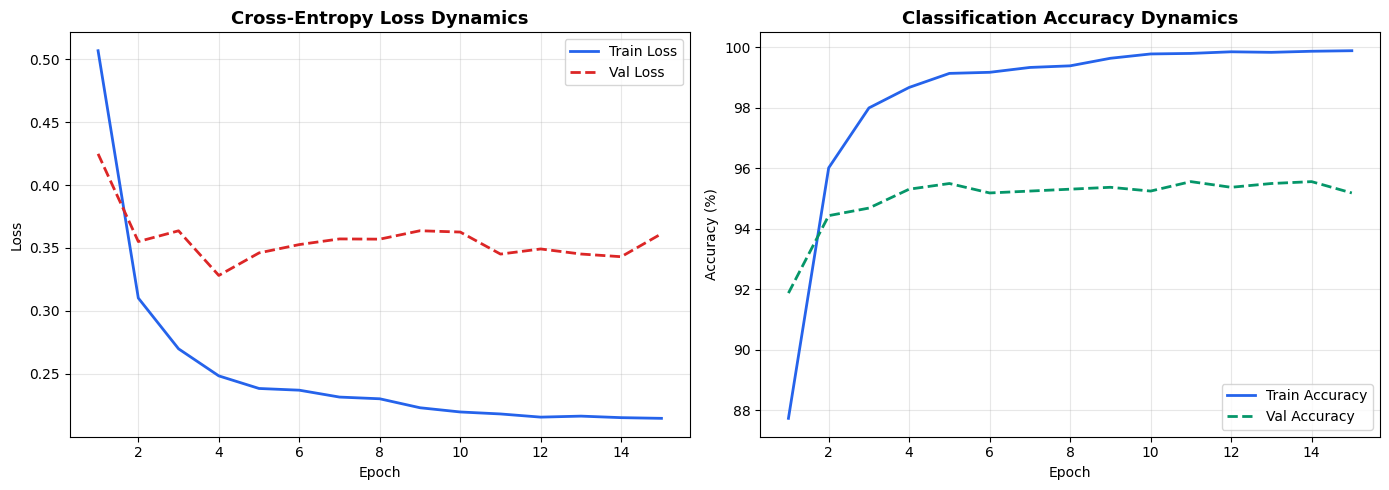

In [8]:
# 8. Plot Loss & Accuracy Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = range(1, EPOCHS + 1)
ax1.plot(epochs_range, history['train_loss'], label='Train Loss', color='#2563EB', linewidth=2)
ax1.plot(epochs_range, history['val_loss'], label='Val Loss', color='#DC2626', linewidth=2, linestyle='--')
ax1.set_title('Cross-Entropy Loss Dynamics', fontsize=13, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(epochs_range, [acc*100 for acc in history['train_acc']], label='Train Accuracy', color='#2563EB', linewidth=2)
ax2.plot(epochs_range, [acc*100 for acc in history['val_acc']], label='Val Accuracy', color='#059669', linewidth=2, linestyle='--')
ax2.set_title('Classification Accuracy Dynamics', fontsize=13, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


---
## 9. Comprehensive Model Evaluation
We evaluate the optimal checkpoint on the unseen test set, calculating:
* **Confusion Matrix** (identifying potential cross-tumor misclassifications).
* **Multi-Class One-vs-Rest (OvR) ROC-AUC Curves**.
* **Clinical Precision, Recall, and F1-Scores**.


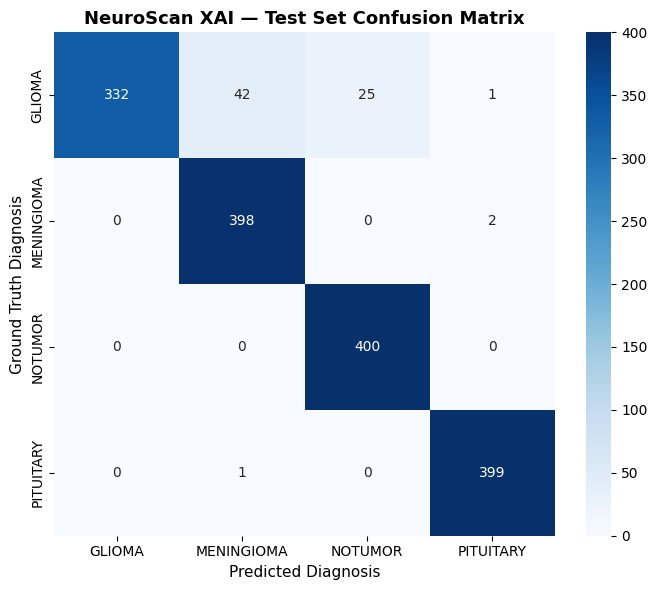


--- Clinical Classification Report ---
              precision    recall  f1-score   support

      GLIOMA     1.0000    0.8300    0.9071       400
  MENINGIOMA     0.9025    0.9950    0.9465       400
     NOTUMOR     0.9412    1.0000    0.9697       400
   PITUITARY     0.9925    0.9975    0.9950       400

    accuracy                         0.9556      1600
   macro avg     0.9591    0.9556    0.9546      1600
weighted avg     0.9591    0.9556    0.9546      1600



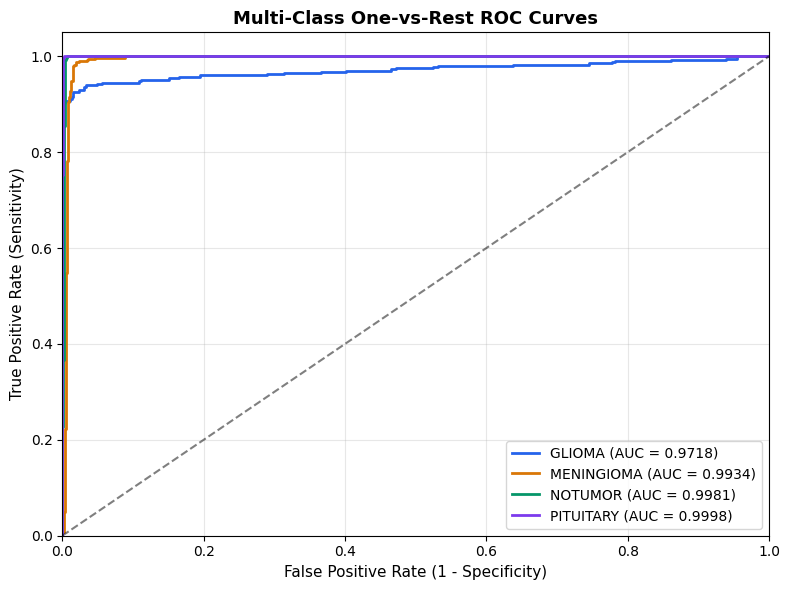

In [9]:
# 9. Test Set Evaluation: Confusion Matrix & ROC-AUC Curves
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize
import seaborn as sns

# Load best checkpoint
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

all_preds = []
all_targets = []
all_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        probs = F.softmax(outputs, dim=1)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)
all_probs = np.array(all_probs)

# 1. Confusion Matrix
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[c.upper() for c in class_names],
            yticklabels=[c.upper() for c in class_names])
plt.title('NeuroScan XAI — Test Set Confusion Matrix', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Diagnosis', fontsize=11)
plt.ylabel('Ground Truth Diagnosis', fontsize=11)
plt.tight_layout()
plt.show()

# 2. Classification Report
print("\n--- Clinical Classification Report ---")
print(classification_report(all_targets, all_preds, target_names=[c.upper() for c in class_names], digits=4))

# 3. Multi-Class ROC Curves
y_bin = label_binarize(all_targets, classes=list(range(len(class_names))))
plt.figure(figsize=(8, 6))

colors = ['#2563EB', '#D97706', '#059669', '#7C3AED']
for i, cls in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_bin[:, i], all_probs[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=colors[i], lw=2, label=f'{cls.upper()} (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.5)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=11)
plt.title('Multi-Class One-vs-Rest ROC Curves', fontsize=13, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
## 10. Explainable AI & Uncertainty Demonstration
For test scans, we display side-by-side:
1. **Original Grayscale MRI**
2. **Grad-CAM Localization Heatmap**
3. **Grad-CAM++ Fine Structure Overlay**
4. **Diagnostic Triage Card with Shannon Entropy ($H$) Uncertainty Rating**:
   $$H(p) = -\sum_{c=1}^4 p_c \log_2(p_c)$$


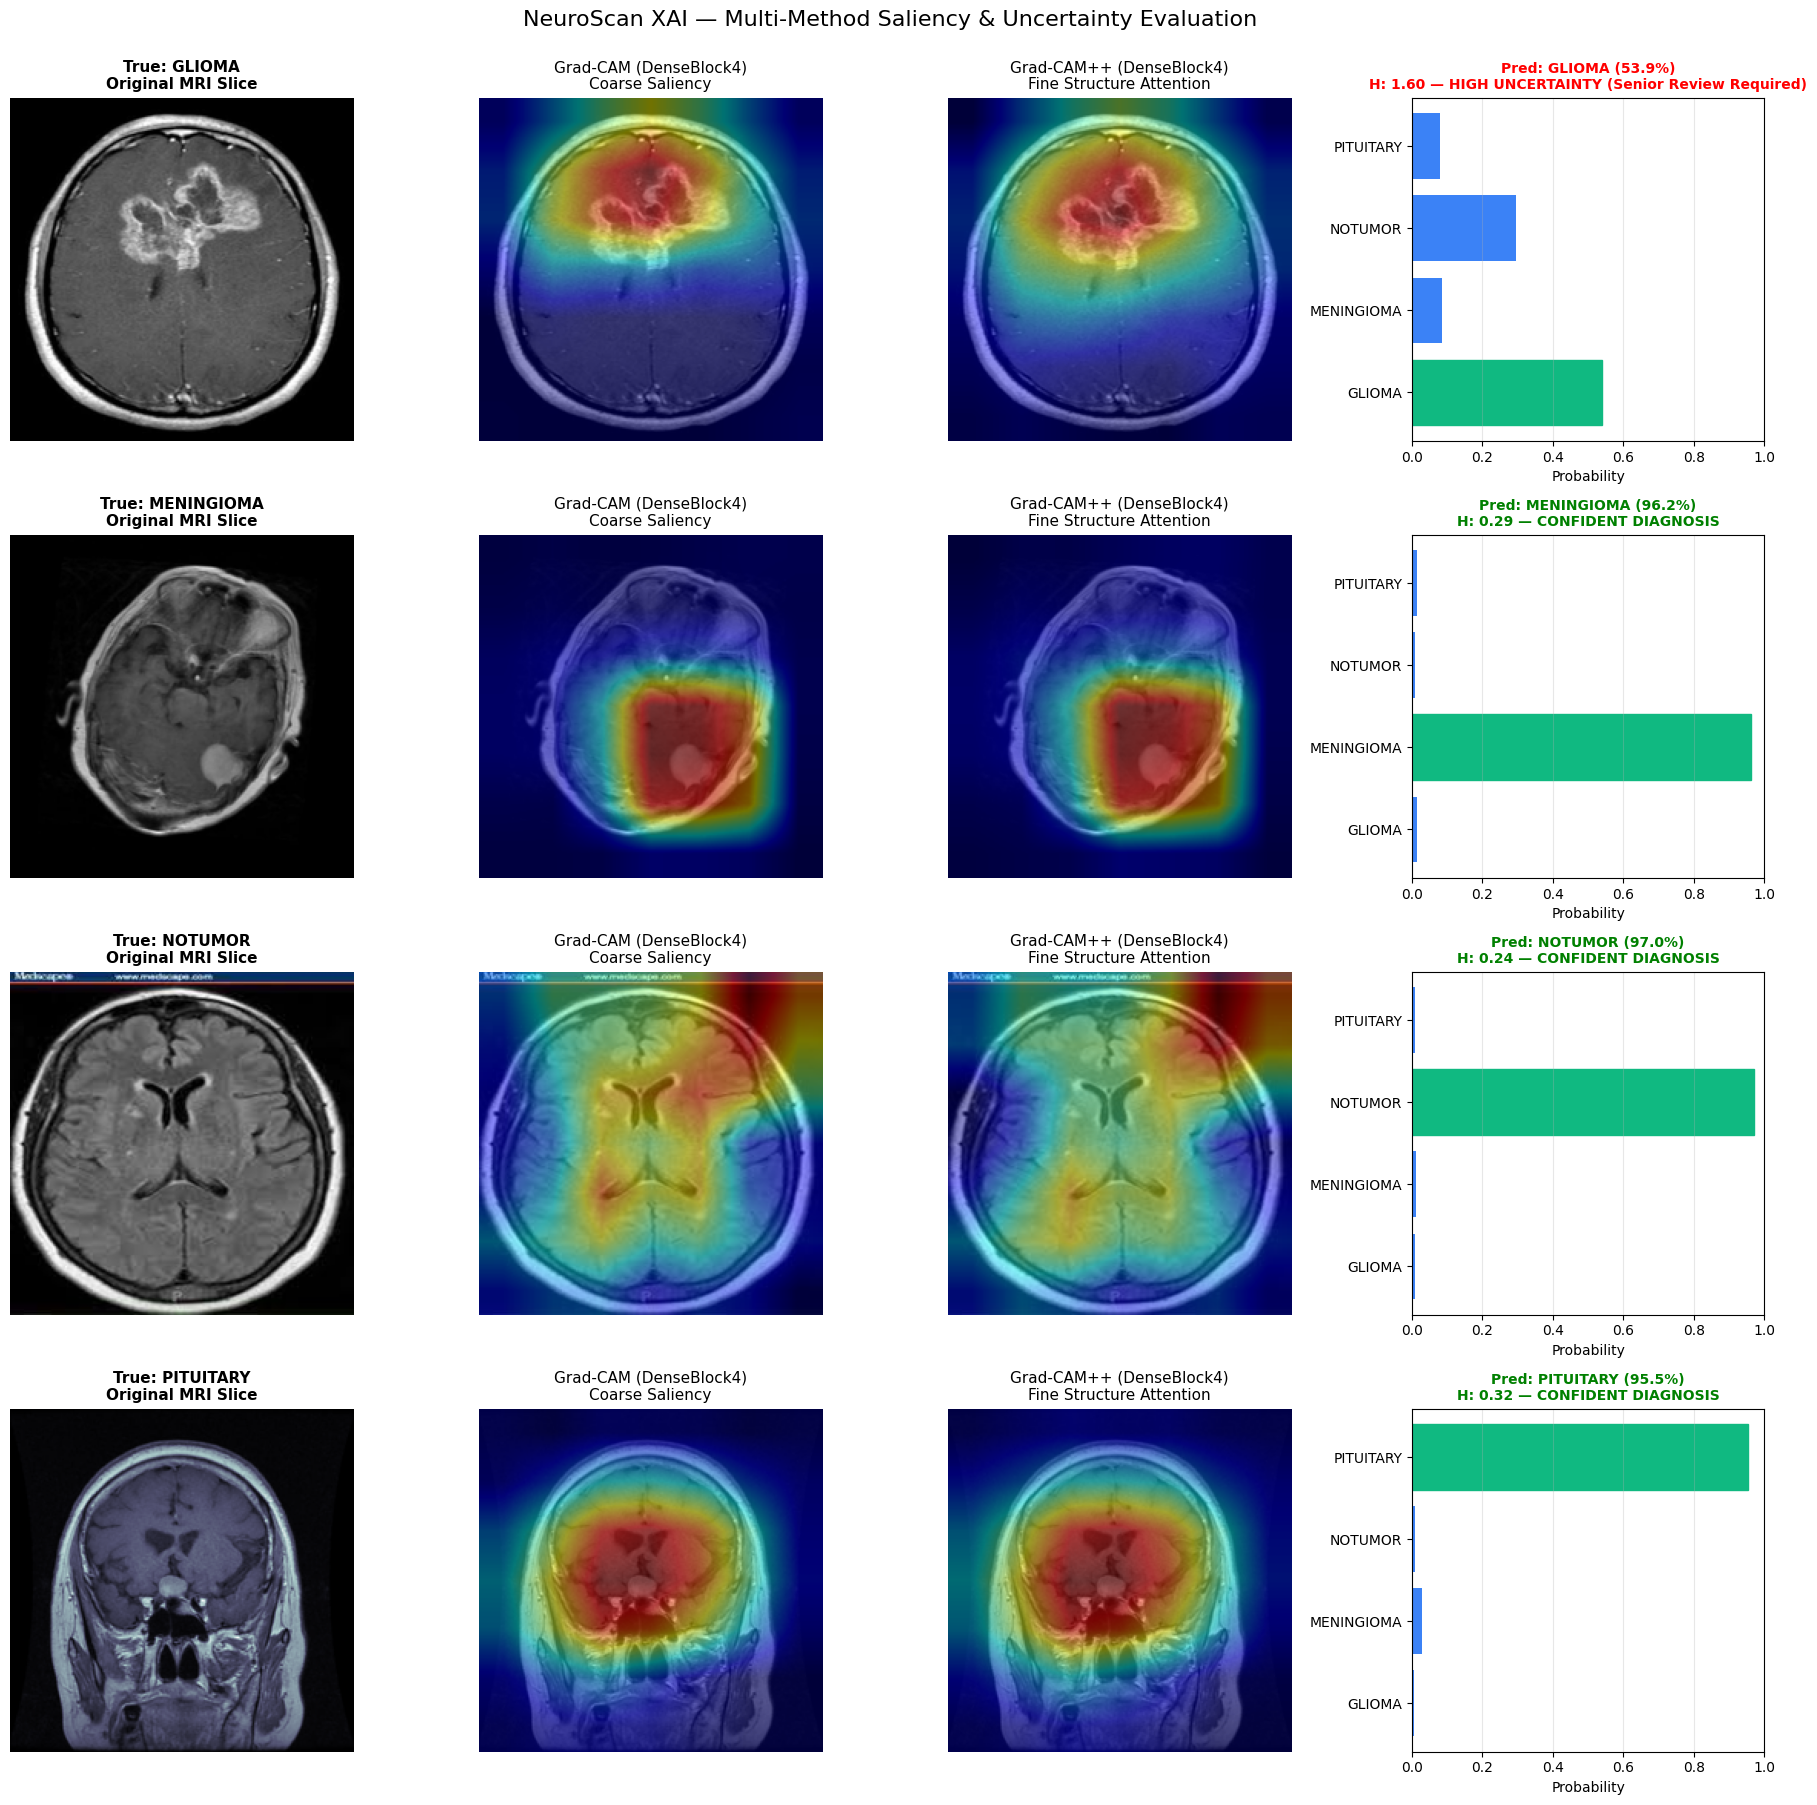

In [10]:
# 10. Saliency Heatmap Visualization and Uncertainty Scoring
def overlay_cam_on_image(img_pil, cam, alpha=0.5):
    img = np.array(img_pil.convert('RGB'))
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    overlay = np.uint8(alpha * heatmap + (1 - alpha) * img)
    return overlay

def compute_entropy(probs):
    eps = 1e-12
    return -np.sum(probs * np.log2(probs + eps))

# Select one sample from each class in test dataset
sample_indices = []
found_classes = set()
for idx, (_, label) in enumerate(test_dataset):
    if label not in found_classes:
        sample_indices.append(idx)
        found_classes.add(label)
    if len(found_classes) == len(class_names):
        break

fig, axes = plt.subplots(len(sample_indices), 4, figsize=(18, 4.5 * len(sample_indices)))

for row_idx, sample_idx in enumerate(sample_indices):
    img_tensor, true_label = test_dataset[sample_idx]
    raw_img_path, _ = test_dataset.samples[sample_idx]
    raw_pil = Image.open(raw_img_path).resize(IMAGE_SIZE)

    input_t = img_tensor.unsqueeze(0).to(device)

    # Generate Grad-CAM and Grad-CAM++
    cam_g, logits = xai_engine.generate_gradcam(input_t)
    cam_gpp, _ = xai_engine.generate_gradcam_plus_plus(input_t)

    probs = F.softmax(logits, dim=1).detach().cpu().numpy()[0]
    pred_class_idx = np.argmax(probs)
    pred_class_name = class_names[pred_class_idx]
    conf = probs[pred_class_idx]

    # Calculate Shannon Entropy
    entropy = compute_entropy(probs)
    if entropy < 0.40:
        uncertainty_status = "CONFIDENT DIAGNOSIS"
        status_color = 'green'
    elif entropy < 0.85:
        uncertainty_status = "MODERATE UNCERTAINTY (Review Recommended)"
        status_color = 'orange'
    else:
        uncertainty_status = "HIGH UNCERTAINTY (Senior Review Required)"
        status_color = 'red'

    overlay_g = overlay_cam_on_image(raw_pil, cam_g, alpha=0.45)
    overlay_gpp = overlay_cam_on_image(raw_pil, cam_gpp, alpha=0.45)

    # Plot 1: Original MRI
    axes[row_idx, 0].imshow(raw_pil, cmap='bone')
    axes[row_idx, 0].set_title(f"True: {class_names[true_label].upper()}\nOriginal MRI Slice", fontsize=11, fontweight='bold')
    axes[row_idx, 0].axis('off')

    # Plot 2: Grad-CAM
    axes[row_idx, 1].imshow(overlay_g)
    axes[row_idx, 1].set_title(f"Grad-CAM (DenseBlock4)\nCoarse Saliency", fontsize=11)
    axes[row_idx, 1].axis('off')

    # Plot 3: Grad-CAM++
    axes[row_idx, 2].imshow(overlay_gpp)
    axes[row_idx, 2].set_title(f"Grad-CAM++ (DenseBlock4)\nFine Structure Attention", fontsize=11)
    axes[row_idx, 2].axis('off')

    # Plot 4: Probabilities Bar Chart
    bars = axes[row_idx, 3].barh([c.upper() for c in class_names], probs, color='#3B82F6')
    bars[pred_class_idx].set_color('#10B981' if pred_class_idx == true_label else '#EF4444')
    axes[row_idx, 3].set_xlim([0, 1.0])
    axes[row_idx, 3].set_xlabel("Probability")
    axes[row_idx, 3].set_title(f"Pred: {pred_class_name.upper()} ({conf*100:.1f}%)\nH: {entropy:.2f} — {uncertainty_status}",
                               fontsize=10, fontweight='bold', color=status_color)
    axes[row_idx, 3].grid(True, axis='x', alpha=0.3)

plt.suptitle("NeuroScan XAI — Multi-Method Saliency & Uncertainty Evaluation", fontsize=16, y=1.00)
plt.tight_layout()
plt.show()


---
## 11. Packaging Weights & Metadata for the Full-Stack Application
We serialize:
1. `best_densenet121.pth` (Model weights).
2. `model_metadata.json` (Diagnostic class schema, normalization hyperparameters, and calibrated entropy thresholds).
3. `neuroscan_model_package.zip` (Downloadable deployment bundle for the FastAPI backend).


In [11]:
# 11. Metadata Serialization & Colab Download Bundle
metadata = {
    "project": "NeuroScan XAI",
    "architecture": "DenseNet-121",
    "num_classes": len(class_names),
    "classes": class_names,
    "input_resolution": [224, 224],
    "normalization": {
        "mean": [0.485, 0.456, 0.406],
        "std": [0.229, 0.224, 0.225]
    },
    "best_validation_accuracy": float(best_val_acc),
    "entropy_thresholds": {
        "confident_max": 0.40,
        "uncertain_min": 0.85
    },
    "target_layer_hook": "features.denseblock4"
}

with open("model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print("Saved model_metadata.json.")

# Package into zip file
!zip -q -9 neuroscan_model_package.zip best_densenet121.pth model_metadata.json
print("Packaged neuroscan_model_package.zip successfully.")

# Automated Colab Download Trigger
try:
    from google.colab import files
    print("\nTriggering browser download of neuroscan_model_package.zip...")
    files.download("neuroscan_model_package.zip")
except ImportError:
    print("\nNot running inside Google Colab. The package is saved locally as 'neuroscan_model_package.zip'.")


Saved model_metadata.json.
Packaged neuroscan_model_package.zip successfully.

Triggering browser download of neuroscan_model_package.zip...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>